In [52]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fastf1
from src.track import track_geometry
from src.params import CAR_2022, CAR_2022_FIT, RANGES_2022, G, RWD_2022, RWD_RANGES_2022
from src.solver import solve_lap, lap_time
from src.vehicle import rear_share, a_brake
from src.correlation import (cum_time, accel_profile, regrid, apex_table,
                             sector_boundaries, sector_times,
                             ZONES, classify_zones, segment_table, 
                             zone_totals, channel_on_grid)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
fastf1.Cache.enable_cache('../cache')
fastf1.set_log_level('WARNING')
session = fastf1.get_session(2022, 'Spain', 'Q')
session.load()

sets = {'Sourced': CAR_2022, 'Identified': CAR_2022_FIT}

drivers = {}
for drv in ['LEC', 'VER']:
    lap = session.laps.pick_drivers(drv).pick_fastest()
    geo = track_geometry(lap)
    w = lap.get_weather_data()
    rho = w['Pressure'] * 100 / (287.05 * (w['AirTemp'] + 273.15))
    drivers[drv] = {'lap': lap, 'geo': geo, 'rho': rho,
                    'v_start': geo['v'].iloc[0], 'v_end': geo['v'].iloc[-1]}
    print(f"{drv}: lap {lap['LapTime'].total_seconds():.3f} s, "
          f"rho = {rho:.3f} kg/m^3, grid end s = {geo['s'].iloc[-1]:.1f} m")

c:\Users\Ryan\Documents\f1-lapsim\.venv\Lib\site-packages\fastf1\req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


LEC: lap 78.750 s, rho = 1.135 kg/m^3, grid end s = 4584.0 m
VER: lap 79.073 s, rho = 1.136 kg/m^3, grid end s = 4566.0 m


In [25]:
# =================================
# Regression check
# =================================

d = drivers['LEC']
geo = d['geo']
s = geo['s'].to_numpy()
v_meas = geo['v'].to_numpy()

print(f"cum_time end:   {cum_time(s, v_meas)[-1]:.3f} s")
print(f"lap_time:       {lap_time(s, v_meas):.3f} s")
print(f"peak brake:     {-accel_profile(s, v_meas).min() / G:.2f} g")
t_rg = solve_lap(regrid(geo, 2.0), CAR_2022, d['rho'], d['v_start'], d['v_end'])['t']
print(f"regrid ds=2 m:  {t_rg:.3f} s")

apex_table(geo, d['rho'], CAR_2022, prominence_kmh=10).round(2)

cum_time end:   77.835 s
lap_time:       77.835 s
peak brake:     5.90 g
regrid ds=2 m:  80.690 s


,s,r_min,v_meas_kmh,v_apex_kmh,v2,a_lat,a_lat_g,mu_req
0,824.0,49.84,156.69,124.11,1894.48,38.01,3.87,2.12
1,1692.0,53.64,150.46,131.38,1746.73,32.56,3.32,1.88
2,2084.0,33.92,106.43,94.81,874.04,25.77,2.63,1.90
3,2514.0,43.65,155.70,112.57,1870.65,42.85,4.37,2.40
4,2854.0,86.20,246.33,207.06,4681.80,54.32,5.54,1.82
5,3448.0,32.65,116.53,92.50,1047.85,32.10,3.27,2.24
6,3724.0,45.58,131.00,116.13,1324.15,29.05,2.96,1.88
7,3976.0,37.44,132.19,101.23,1348.38,36.01,3.67,2.31
8,4092.0,21.26,84.79,71.16,554.69,26.09,2.66,2.14


In [26]:
# =================================
# Where are the timing lines
# =================================

for drv, d in drivers.items():
    b = sector_boundaries(d['lap'])
    d['bounds'] = b
    s_end = d['geo']['s'].iloc[-1]
    print(f"{drv}: start {b['start']:7.1f}   S1|S2 {b['s12']:7.1f}   "
          f"S2|S3 {b['s23']:7.1f}   end {b['end']:7.1f}   "
          f"(grid 0 to {s_end:.1f} m)")
    print(f"      line-to-line distance: {b['end'] - b['start']:.1f} m")

LEC: start     0.0   S1|S2  1589.7   S2|S3  3335.4   end  4585.0   (grid 0 to 4584.0 m)
      line-to-line distance: 4585.0 m
VER: start     0.0   S1|S2  1581.1   S2|S3  3328.6   end  4567.0   (grid 0 to 4566.0 m)
      line-to-line distance: 4567.0 m


In [27]:
# =================================
# Sector times
# =================================

rows = []
for drv, d in drivers.items():
    geo, lap, b = d['geo'], d['lap'], d['bounds']
    s = geo['s'].to_numpy()

    official = [lap[f'Sector{k}Time'].total_seconds() for k in (1, 2, 3)]
    rows.append({'driver': drv, 'run': 'Official', **dict(zip(['S1', 'S2', 'S3'], official))})

    meas = sector_times(s, geo['v'].to_numpy(), b)
    rows.append({'driver': drv, 'run': 'Measured (grid)', **dict(zip(['S1', 'S2', 'S3'], meas))})

    d['results'] = {}
    for name, car in sets.items():
        res = solve_lap(geo, car, d['rho'], d['v_start'], d['v_end'])
        d['results'][name] = res
        sim = sector_times(s, res['v'], b)
        rows.append({'driver': drv, 'run': name, **dict(zip(['S1', 'S2', 'S3'], sim))})

table = pd.DataFrame(rows)
table['lap'] = table[['S1', 'S2', 'S3']].sum(axis=1)
table.round(3)

,driver,run,S1,S2,S3,lap
0,LEC,Official,22.004,29.410,27.336,78.750
1,LEC,Measured (grid),21.684,29.279,26.872,77.835
2,LEC,Sourced,21.824,30.938,27.928,80.690
3,LEC,Identified,20.279,27.508,24.143,71.930
4,VER,Official,21.978,29.684,27.411,79.073
5,VER,Measured (grid),21.570,29.530,26.774,77.874
6,VER,Sourced,22.048,30.792,27.633,80.473
7,VER,Identified,20.417,27.431,24.045,71.893


In [28]:
# =================================
# Correlation table
# =================================

cols = ['S1', 'S2', 'S3', 'lap']
meas = table[table['run'] == 'Measured (grid)'].set_index('driver')[cols]
for name in sets:
    sim = table[table['run'] == name].set_index('driver')[cols]
    print(f"\n{name}: model − measured on the same grid [s]")
    print((sim - meas).round(3))


Sourced: model − measured on the same grid [s]
           S1     S2     S3    lap
driver                            
LEC     0.140  1.659  1.056  2.855
VER     0.478  1.262  0.860  2.600

Identified: model − measured on the same grid [s]
           S1     S2     S3    lap
driver                            
LEC    -1.404 -1.771 -2.729 -5.904
VER    -1.154 -2.099 -2.729 -5.981


In [29]:
# =================================
# Directly measuring the uncovered ends
# =================================

for drv, d in drivers.items():
    lap = d['lap']
    pos = lap.get_pos_data()
    gap_start = (pos['SessionTime'].iloc[0] - lap['LapStartTime']).total_seconds()
    gap_end = (lap['Time'] - pos['SessionTime'].iloc[-1]).total_seconds()
    v0, v1 = d['v_start'], d['v_end']
    print(f"{drv}: start line -> first sample {gap_start:.3f} s (~{gap_start*v0:.0f} m), "
          f"last sample -> finish line {gap_end:.3f} s (~{gap_end*v1:.0f} m)")

LEC: start line -> first sample 0.160 s (~13 m), last sample -> finish line 0.030 s (~2 m)
VER: start line -> first sample 0.202 s (~16 m), last sample -> finish line 0.151 s (~12 m)


In [30]:
# =================================
# Classifying a solution then checking 
# that it makes sense
# =================================

d = drivers['LEC']
geo, res = d['geo'], d['results']['Sourced']
s = geo['s'].to_numpy()
zone = classify_zones(geo, res, CAR_2022, d['rho'])
a_mod = accel_profile(s, res['v'])

for z in ZONES:
    pts = zone == z
    seg = pts[:-1]
    print(f"{z:12s} {pts.sum():5d} pts ({pts.mean()*100:4.1f} %)   "
          f"v {res['v'][pts].min()*3.6:4.0f}-{res['v'][pts].max()*3.6:4.0f} km/h   "
          f"a {a_mod[seg].min()/G:+.2f} to {a_mod[seg].max()/G:+.2f} g")

cornering       15 pts ( 0.7 %)   v   71- 224 km/h   a -0.42 to -0.04 g
braking        439 pts (19.1 %)   v   71- 327 km/h   a -7.74 to -0.04 g
accel_grip     266 pts (11.6 %)   v   71- 227 km/h   a -0.21 to +2.28 g
accel_power   1573 pts (68.6 %)   v  130- 328 km/h   a -6.17 to +2.20 g


In [31]:
# =================================
# Zone totals for both drivers and both sets
# =================================

seg_tables = {}
for drv, d in drivers.items():
    geo = d['geo']
    s = geo['s'].to_numpy()
    v_meas = geo['v'].to_numpy()
    for name, car in sets.items():
        res = d['results'][name]
        zone = classify_zones(geo, res, car, d['rho'])
        seg = segment_table(s, res['v'], v_meas, zone, d['bounds'])
        seg_tables[(drv, name)] = seg
        by_zone = seg.groupby('zone')[['dt', 'ds']].sum().reindex(ZONES)
        print(f"\n{drv}, {name}: total {seg['dt'].sum():+.3f} s")
        print(by_zone.round(3))


LEC, Sourced: total +2.855 s
                dt      ds
zone                      
cornering    0.181    30.0
braking      2.775   876.0
accel_grip   1.300   532.0
accel_power -1.401  3146.0

LEC, Identified: total -5.904 s
                dt      ds
zone                      
cornering    0.031    26.0
braking     -0.269   674.0
accel_grip  -0.576   316.0
accel_power -5.091  3568.0

VER, Sourced: total +2.600 s
                dt      ds
zone                      
cornering    0.191    30.0
braking      3.089   878.0
accel_grip   1.112   544.0
accel_power -1.793  3114.0

VER, Identified: total -5.981 s
                dt      ds
zone                      
cornering    0.044    24.0
braking     -0.042   684.0
accel_grip  -0.493   292.0
accel_power -5.490  3566.0


In [32]:
# =================================
# Zone x sector 
# =================================

for drv in drivers:
    seg = seg_tables[(drv, 'Sourced')]
    pt = seg.pivot_table(index='zone', columns='sector', values='dt',
                         aggfunc='sum', margins=True, margins_name='Total')
    print(f"\n{drv}, Sourced: model − measured [s] by zone and sector")
    print(pt.reindex(ZONES + ['Total']).round(3))


LEC, Sourced: model − measured [s] by zone and sector
sector          S1     S2     S3  Total
zone                                   
cornering    0.022  0.062  0.098  0.181
braking      0.267  1.145  1.363  2.775
accel_grip   0.198  0.647  0.454  1.300
accel_power -0.347 -0.195 -0.859 -1.401
Total        0.140  1.659  1.056  2.855

VER, Sourced: model − measured [s] by zone and sector
sector          S1     S2     S3  Total
zone                                   
cornering    0.027  0.060  0.104  0.191
braking      0.321  1.245  1.524  3.089
accel_grip   0.210  0.517  0.385  1.112
accel_power -0.080 -0.559 -1.154 -1.793
Total        0.479  1.262  0.859  2.600


In [33]:
# =================================
# Checking labelling convention 
# =================================

d = drivers['LEC']
res = d['results']['Sourced']
zone = classify_zones(d['geo'], res, CAR_2022, d['rho'])
seg = seg_tables[('LEC', 'Sourced')]

start_lab = seg.groupby('zone')['dt'].sum().reindex(ZONES)
end_lab = seg.assign(zone=zone[1:]).groupby('zone')['dt'].sum().reindex(ZONES)
pd.DataFrame({'start label': start_lab, 'end label': end_lab,
              'difference': end_lab - start_lab}).round(3)

,start label,end label,difference
zone,,,
cornering,0.181,0.184,0.003
braking,2.775,2.544,-0.231
accel_grip,1.300,1.480,0.180
accel_power,-1.401,-1.352,0.049


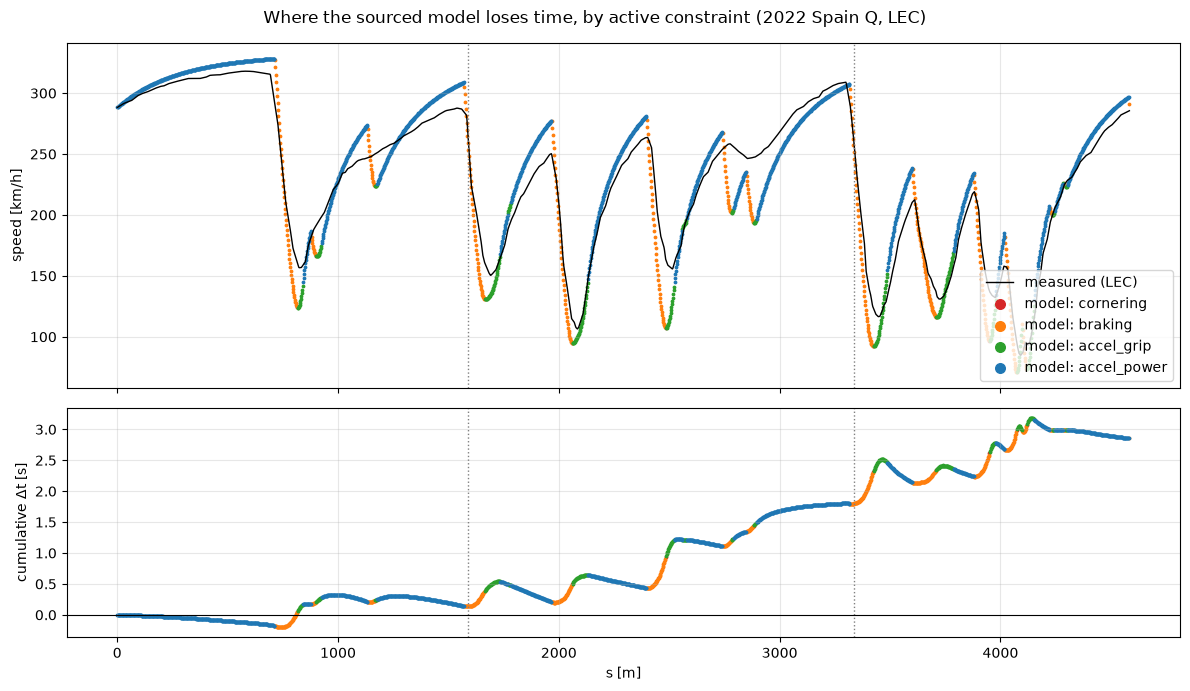

In [34]:
# =================================
# Attribution figure 
# =================================

d = drivers['LEC']
geo, res = d['geo'], d['results']['Sourced']
seg = seg_tables[('LEC', 'Sourced')]
cum_dt = seg['dt'].cumsum().to_numpy()
colours = {'cornering': 'tab:red', 'braking': 'tab:orange',
           'accel_grip': 'tab:green', 'accel_power': 'tab:blue'}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                               gridspec_kw={'height_ratios': [3, 2]})
ax1.plot(geo['s'], geo['v'] * 3.6, color='k', lw=1, label='measured (LEC)')
for z in ZONES:
    m = (seg['zone'] == z).to_numpy()
    ax1.scatter(seg['s'][m], res['v'][:-1][m] * 3.6, s=3, color=colours[z], label=f'model: {z}')
    ax2.scatter(seg['s'][m], cum_dt[m], s=3, color=colours[z])

for ax in (ax1, ax2):
    for k in ('s12', 's23'):
        ax.axvline(d['bounds'][k], color='grey', ls=':', lw=1)
    ax.grid(alpha=0.3)
ax2.axhline(0, color='k', lw=0.8)

ax1.set_ylabel('speed [km/h]')
ax1.legend(loc='lower right', markerscale=4)
ax2.set_xlabel('s [m]')
ax2.set_ylabel('cumulative Δt [s]')
fig.suptitle('Where the sourced model loses time, by active constraint (2022 Spain Q, LEC)')
plt.tight_layout()
plt.savefig('../figures/05_zone_attribution.png', dpi=200)
plt.show()

In [35]:
# =================================
# Attribution figure 
# =================================

for (drv, name), seg in seg_tables.items():
    zt = zone_totals(seg)
    print(f"\n{drv}, {name}: total {zt['dt'].sum():+.3f} s")
    print(zt.round(3))


LEC, Sourced: total +2.855 s
                dt  spread
cornering    0.183   0.001
braking      2.659   0.116
accel_grip   1.390   0.090
accel_power -1.377   0.024

LEC, Identified: total -5.904 s
                dt  spread
cornering    0.033   0.002
braking     -0.329   0.060
accel_grip  -0.524   0.051
accel_power -5.084   0.007

VER, Sourced: total +2.600 s
                dt  spread
cornering    0.193   0.001
braking      2.968   0.121
accel_grip   1.208   0.096
accel_power -1.770   0.024

VER, Identified: total -5.981 s
                dt  spread
cornering    0.045   0.001
braking     -0.108   0.066
accel_grip  -0.435   0.057
accel_power -5.483   0.007


In [36]:
# =================================
# Sweeping Leclerc 
# =================================

d = drivers['LEC']
geo, rho = d['geo'], d['rho']
s = geo['s'].to_numpy()
base = d['results']['Sourced']
t0 = sector_times(s, base['v'], d['bounds'])

rows = []
for p, (lo, hi) in RANGES_2022.items():
    for end, val in (('low', lo), ('high', hi)):
        res_p = solve_lap(geo, {**CAR_2022, p: val}, rho, d['v_start'], d['v_end'])
        dsec = sector_times(s, res_p['v'], d['bounds']) - t0
        a_p = accel_profile(s, res_p['v'])
        rows.append({'param': p, 'end': end, 'value': val,
                     'dS1': dsec[0], 'dS2': dsec[1], 'dS3': dsec[2],
                     'dlap': res_p['t'] - base['t'],
                     'top_kmh': res_p['v'].max() * 3.6,
                     'brake_g': -a_p.min() / G})

sens = pd.DataFrame(rows)
sens.round(3)

,param,end,value,dS1,dS2,dS3,dlap,top_kmh,brake_g
0,m,low,803.0,-0.036,-0.061,-0.047,-0.144,328.366,7.676
1,m,high,818.0,0.070,0.120,0.093,0.283,328.166,7.572
2,ClA,low,4.8,1.056,1.703,1.413,4.172,328.095,6.741
3,ClA,high,7.3,-0.937,-1.365,-1.068,-3.370,328.436,8.558
4,mu_y,low,1.4,1.110,2.121,2.061,5.292,328.203,7.711
5,mu_y,high,1.8,-0.951,-1.658,-1.554,-4.164,328.386,7.526
6,CdA,low,1.0,-0.741,-0.423,-0.167,-1.332,363.290,9.050
7,CdA,high,1.8,0.450,0.265,0.105,0.820,311.295,7.045
8,P_max,low,650000.0,0.111,0.117,0.054,0.282,325.243,7.486
9,P_max,high,750000.0,-0.406,-0.410,-0.187,-1.003,339.935,8.289


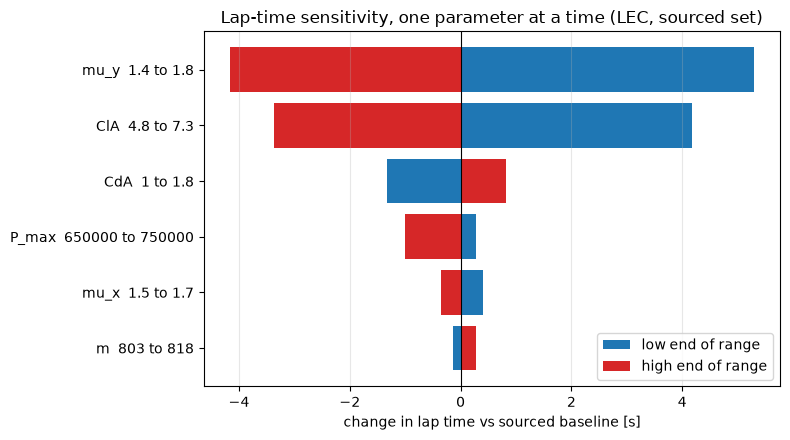

In [37]:
# =================================
# Tornado plot 
# =================================

tor = sens.pivot(index='param', columns='end', values='dlap')
tor = tor.loc[(tor['high'] - tor['low']).abs().sort_values().index]

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(tor))
ax.barh(y, tor['low'], color='tab:blue', label='low end of range')
ax.barh(y, tor['high'], color='tab:red', label='high end of range')
ax.set_yticks(y)
ax.set_yticklabels([f"{p}  {RANGES_2022[p][0]:g} to {RANGES_2022[p][1]:g}" for p in tor.index])
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('change in lap time vs sourced baseline [s]')
ax.set_title('Lap-time sensitivity, one parameter at a time (LEC, sourced set)')
ax.grid(alpha=0.3, axis='x')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../figures/05_sensitivity.png', dpi=200)
plt.show()

In [38]:
# =================================
# Regression check with the new function 
# =================================

d = drivers['LEC']
s = d['geo']['s'].to_numpy()
v_chk = channel_on_grid(d['lap'], s, 'Speed') / 3.6
print(f"max |v_chk - geo['v']| = {np.max(np.abs(v_chk - d['geo']['v'].to_numpy())):.2e} m/s")

max |v_chk - geo['v']| = 1.42e-14 m/s


In [39]:
# =================================
# The fit for both drivers
# =================================

m = CAR_2022['m']
fits = {}
for drv, d in drivers.items():
    geo, lap, rho = d['geo'], d['lap'], d['rho']
    s = geo['s'].to_numpy()
    v = geo['v'].to_numpy()
    thr = channel_on_grid(lap, s, 'Throttle')
    drs = channel_on_grid(lap, s, 'DRS')

    a = accel_profile(s, v)                    # one value per segment
    v_mid = 0.5 * (v[:-1] + v[1:])
    sel = ((thr[:-1] >= 99) & (thr[1:] >= 99)
           & (v_mid > 150 / 3.6)
           & (geo['r'].to_numpy()[:-1] > 500))

    x = v_mid[sel]**3
    y = a[sel] * v_mid[sel]
    (b1, b0), cov = np.polyfit(x, y, 1, cov=True)
    se1, se0 = np.sqrt(np.diag(cov))

    P_fit = m * b0
    CdA_fit = -2 * m * b1 / rho
    v_term = (2 * P_fit / (rho * CdA_fit))**(1 / 3)
    fits[drv] = {'P_max': P_fit, 'CdA': CdA_fit, 'x': x, 'y': y, 'rho': rho}

    print(f"{drv}: {sel.sum()} segments, {v_mid[sel].min()*3.6:.0f}-{v_mid[sel].max()*3.6:.0f} km/h, "
          f"DRS open on {(drs[:-1][sel] >= 10).mean()*100:.0f} %")
    print(f"     P_eff = {P_fit/1e3:.0f} ± {m*se0/1e3:.0f} kW   "
          f"CdA_eff = {CdA_fit:.2f} ± {2*m*se1/rho:.2f} m^2   "
          f"terminal {v_term*3.6:.0f} km/h   (± are polyfit SEs, ~3x too small)")

LEC: 896 segments, 172-318 km/h, DRS open on 65 %
     P_eff = 511 ± 9 kW   CdA_eff = 1.23 ± 0.03 m^2   terminal 324 km/h   (± are polyfit SEs, ~3x too small)
VER: 890 segments, 161-321 km/h, DRS open on 65 %
     P_eff = 476 ± 7 kW   CdA_eff = 1.06 ± 0.03 m^2   terminal 332 km/h   (± are polyfit SEs, ~3x too small)


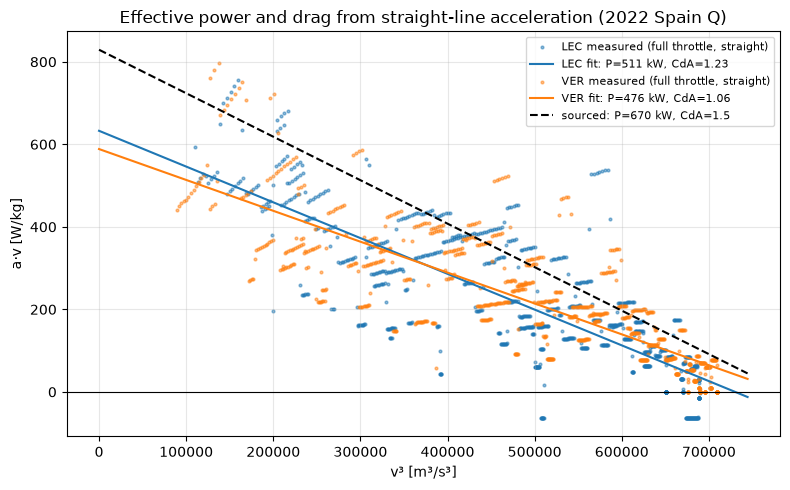

In [40]:
# =================================
# Identification figure
# =================================

fig, ax = plt.subplots(figsize=(8, 5))
x_line = np.linspace(0, max(f['x'].max() for f in fits.values()) * 1.05, 100)
for drv, f in fits.items():
    ax.scatter(f['x'], f['y'], s=4, alpha=0.5, label=f'{drv} measured (full throttle, straight)')
    ax.plot(x_line, f['P_max'] / m - f['rho'] * f['CdA'] / (2 * m) * x_line,
            label=f"{drv} fit: P={f['P_max']/1e3:.0f} kW, CdA={f['CdA']:.2f}")
rho_l = fits['LEC']['rho']
ax.plot(x_line, CAR_2022['P_max'] / m - rho_l * CAR_2022['CdA'] / (2 * m) * x_line, 'k--',
        label=f"sourced: P={CAR_2022['P_max']/1e3:.0f} kW, CdA={CAR_2022['CdA']}")
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('v³ [m³/s³]')
ax.set_ylabel('a·v [W/kg]')
ax.set_title('Effective power and drag from straight-line acceleration (2022 Spain Q)')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('../figures/05_power_drag_identification.png', dpi=200)
plt.show()

In [41]:
# =================================
# Re-solve using the identified
# straight line parameters
# =================================

pd_fit = {'P_max': fits['LEC']['P_max'], 'CdA': fits['LEC']['CdA']}   # fitted on LEC

for drv, d in drivers.items():
    geo = d['geo']
    s = geo['s'].to_numpy()
    v_meas = geo['v'].to_numpy()
    t_meas = lap_time(s, v_meas)
    for name, car in sets.items():
        car_pd = {**car, **pd_fit}                     # DIAGNOSTIC ONLY
        res = solve_lap(geo, car_pd, d['rho'], d['v_start'], d['v_end'])
        zone = classify_zones(geo, res, car_pd, d['rho'])
        zt = zone_totals(segment_table(s, res['v'], v_meas, zone, d['bounds']))
        a_pd = accel_profile(s, res['v'])
        print(f"\n{drv}, {name} grip + LEC-identified P/CdA: lap {res['t']:.3f} s "
              f"(delta {res['t'] - t_meas:+.3f}), top {res['v'].max()*3.6:.1f} km/h, "
              f"peak brake {-a_pd.min()/G:.2f} g")
        print(zt.round(3))


LEC, Sourced grip + LEC-identified P/CdA: lap 82.508 s (delta +4.673), top 319.1 km/h, peak brake 7.21 g
                dt  spread
cornering    0.183   0.002
braking      2.774   0.106
accel_grip   1.388   0.078
accel_power  0.329   0.026

LEC, Identified grip + LEC-identified P/CdA: lap 73.975 s (delta -3.860), top 319.4 km/h, peak brake 7.77 g
                dt  spread
cornering    0.034   0.002
braking     -0.192   0.054
accel_grip  -0.239   0.041
accel_power -3.463   0.011

VER, Sourced grip + LEC-identified P/CdA: lap 82.371 s (delta +4.498), top 319.5 km/h, peak brake 7.38 g
                dt  spread
cornering    0.195   0.001
braking      3.092   0.113
accel_grip   1.272   0.088
accel_power -0.062   0.023

VER, Identified grip + LEC-identified P/CdA: lap 74.000 s (delta -3.873), top 319.8 km/h, peak brake 7.75 g
                dt  spread
cornering    0.045   0.002
braking      0.061   0.058
accel_grip  -0.243   0.045
accel_power -3.737   0.012


In [42]:
# =================================
# Where in the speed range is the
# power zone time gained
# =================================

d = drivers['LEC']
geo = d['geo']
s = geo['s'].to_numpy()
v_meas = geo['v'].to_numpy()
bands = [0, 150, 200, 250, 300, 400]

for name, car in sets.items():
    car_pd = {**car, **pd_fit}                     # for diagnosis
    res = solve_lap(geo, car_pd, d['rho'], d['v_start'], d['v_end'])
    zone = classify_zones(geo, res, car_pd, d['rho'])
    seg = segment_table(s, res['v'], v_meas, zone, d['bounds'])
    seg['v_kmh'] = res['v'][:-1] * 3.6
    pw = seg[seg['zone'] == 'accel_power']
    print(f"\nLEC, {name} grip + identified P/CdA: power zone starts at "
          f"{pw['v_kmh'].min():.0f} km/h, total {pw['dt'].sum():+.3f} s")
    print(pw.groupby(pd.cut(pw['v_kmh'], bands), observed=False)[['dt', 'ds']].sum().round(3))


LEC, Sourced grip + identified P/CdA: power zone starts at 107 km/h, total +0.302 s
               dt      ds
v_kmh                    
(0, 150]   -0.057    92.0
(150, 200] -0.217   456.0
(200, 250]  0.382  1042.0
(250, 300]  0.188  1138.0
(300, 400]  0.006   578.0

LEC, Identified grip + identified P/CdA: power zone starts at 107 km/h, total -3.474 s
               dt      ds
v_kmh                    
(0, 150]   -0.391    76.0
(150, 200] -1.300   448.0
(200, 250] -0.958   898.0
(250, 300] -0.601  1450.0
(300, 400] -0.224   822.0


In [43]:
# =================================
# Finding if the driver was at full 
# throttle where the model is power limited
# =================================

d = drivers['LEC']
geo = d['geo']
s = geo['s'].to_numpy()
v_meas = geo['v'].to_numpy()
thr = channel_on_grid(d['lap'], s, 'Throttle')

for name, car in sets.items():
    car_pd = {**car, **pd_fit}                               # DIAGNOSTIC ONLY
    res = solve_lap(geo, car_pd, d['rho'], d['v_start'], d['v_end'])
    zone = classify_zones(geo, res, car_pd, d['rho'])
    seg = segment_table(s, res['v'], v_meas, zone, d['bounds'])
    seg['v_kmh'] = res['v'][:-1] * 3.6
    seg['thr'] = thr[:-1]
    seg['full'] = thr[:-1] >= 99
    seg['curved'] = geo['r'].to_numpy()[:-1] < 500

    pw = seg[seg['zone'] == 'accel_power']
    g = pw.groupby(pd.cut(pw['v_kmh'], bands), observed=False)
    out = g[['dt', 'ds']].sum().join(g[['thr', 'full', 'curved']].mean())
    out[['full', 'curved']] *= 100
    print(f"\nLEC, {name} grip + identified P/CdA, model power zone")
    print(out.rename(columns={'thr': 'mean thr %', 'full': 'full thr %',
                              'curved': 'curved %'}).round(2))


LEC, Sourced grip + identified P/CdA, model power zone
              dt      ds  mean thr %  full thr %  curved %
v_kmh                                                     
(0, 150]   -0.06    92.0       71.49        0.00     78.26
(150, 200] -0.22   456.0       93.29       36.84     80.26
(200, 250]  0.38  1042.0       97.59       86.56     65.45
(250, 300]  0.19  1138.0       99.23       95.25     22.67
(300, 400]  0.01   578.0       97.79       96.19      0.69

LEC, Identified grip + identified P/CdA, model power zone
              dt      ds  mean thr %  full thr %  curved %
v_kmh                                                     
(0, 150]   -0.39    76.0       48.23        0.00     89.47
(150, 200] -1.30   448.0       82.80       19.64     79.46
(200, 250] -0.96   898.0       97.79       80.62     75.72
(250, 300] -0.60  1450.0       97.78       87.59     37.66
(300, 400] -0.22   822.0       92.91       86.62      5.35


In [44]:
# =================================
# Regression check and check of rear_share
# =================================

d = drivers['LEC']
print(f"Sourced, no RWD keys: {solve_lap(d['geo'], CAR_2022, d['rho'], d['v_start'], d['v_end'])['t']:.3f} s")

v_test = np.array([0.0, 50, 150, 300]) / 3.6
print("rear share at 0/50/150/300 km/h:",
      np.round(rear_share(v_test, {**CAR_2022, **RWD_2022}, d['rho']), 4))

Sourced, no RWD keys: 80.690 s
rear share at 0/50/150/300 km/h: [0.5475 0.5492 0.5572 0.5644]


In [45]:
# =================================
# AWD vs RWD
# =================================

for drv, d in drivers.items():
    geo = d['geo']
    s = geo['s'].to_numpy()
    v_meas = geo['v'].to_numpy()
    t_meas = lap_time(s, v_meas)
    print(f"\n{drv}: measured peak accel {accel_profile(s, v_meas).max()/G:.2f} g")
    for name, car in sets.items():
        for label, extra in (('AWD', {}), ('RWD', RWD_2022)):
            c = {**car, **pd_fit, **extra}                  # DIAGNOSTIC ONLY
            res = solve_lap(geo, c, d['rho'], d['v_start'], d['v_end'])
            zone = classify_zones(geo, res, c, d['rho'])
            zt = zone_totals(segment_table(s, res['v'], v_meas, zone, d['bounds']))
            a = accel_profile(s, res['v'])
            print(f"  {name:10s} {label}: delta {res['t'] - t_meas:+.3f} s, "
                  f"peak accel {a.max()/G:.2f} g | "
                  + "  ".join(f"{z} {zt.loc[z, 'dt']:+.2f}" for z in ZONES))


LEC: measured peak accel 2.08 g
  Sourced    AWD: delta +4.673 s, peak accel 2.03 g | cornering +0.18  braking +2.77  accel_grip +1.39  accel_power +0.33
  Sourced    RWD: delta +6.825 s, peak accel 1.40 g | cornering +0.18  braking +2.82  accel_grip +2.51  accel_power +1.31
  Identified AWD: delta -3.860 s, peak accel 2.08 g | cornering +0.03  braking -0.19  accel_grip -0.24  accel_power -3.46
  Identified RWD: delta -2.962 s, peak accel 1.69 g | cornering +0.04  braking -0.14  accel_grip -0.60  accel_power -2.25

VER: measured peak accel 2.03 g
  Sourced    AWD: delta +4.498 s, peak accel 2.10 g | cornering +0.19  braking +3.09  accel_grip +1.27  accel_power -0.06
  Sourced    RWD: delta +6.631 s, peak accel 1.40 g | cornering +0.19  braking +3.13  accel_grip +2.27  accel_power +1.04
  Identified AWD: delta -3.873 s, peak accel 2.13 g | cornering +0.05  braking +0.06  accel_grip -0.24  accel_power -3.74
  Identified RWD: delta -3.039 s, peak accel 1.68 g | cornering +0.05  braking +

In [46]:
# =================================
# Seeing if Aero balance uncertainty matters
# =================================

d = drivers['LEC']
geo = d['geo']
t_meas = lap_time(geo['s'].to_numpy(), geo['v'].to_numpy())
for name, car in sets.items():
    for w in RWD_RANGES_2022['w_rear']:
        for b in RWD_RANGES_2022['aero_rear']:
            c = {**car, **pd_fit, 'w_rear': w, 'aero_rear': b}   # DIAGNOSTIC ONLY
            t = solve_lap(geo, c, d['rho'], d['v_start'], d['v_end'])['t']
            print(f"{name:10s} w_rear {w:.3f}  aero_rear {b:.2f}: delta {t - t_meas:+.3f} s")

Sourced    w_rear 0.540  aero_rear 0.54: delta +7.012 s
Sourced    w_rear 0.540  aero_rear 0.60: delta +6.755 s
Sourced    w_rear 0.555  aero_rear 0.54: delta +6.900 s
Sourced    w_rear 0.555  aero_rear 0.60: delta +6.657 s
Identified w_rear 0.540  aero_rear 0.54: delta -2.900 s
Identified w_rear 0.540  aero_rear 0.60: delta -2.979 s
Identified w_rear 0.555  aero_rear 0.54: delta -2.945 s
Identified w_rear 0.555  aero_rear 0.60: delta -3.020 s


In [47]:
# =================================
# Re running cell 21 (4 cells above)
# with the new RWD_2022 function
# =================================

d = drivers['LEC']
geo = d['geo']
s = geo['s'].to_numpy()
v_meas = geo['v'].to_numpy()
thr = channel_on_grid(d['lap'], s, 'Throttle')

for name, car in sets.items():
    car_pd = {**car, **pd_fit, **RWD_2022}                   # the update
    res = solve_lap(geo, car_pd, d['rho'], d['v_start'], d['v_end'])
    zone = classify_zones(geo, res, car_pd, d['rho'])
    seg = segment_table(s, res['v'], v_meas, zone, d['bounds'])
    seg['v_kmh'] = res['v'][:-1] * 3.6
    seg['thr'] = thr[:-1]
    seg['full'] = thr[:-1] >= 99
    seg['curved'] = geo['r'].to_numpy()[:-1] < 500

    pw = seg[seg['zone'] == 'accel_power']
    g = pw.groupby(pd.cut(pw['v_kmh'], bands), observed=False)
    out = g[['dt', 'ds']].sum().join(g[['thr', 'full', 'curved']].mean())
    out[['full', 'curved']] *= 100
    print(f"\nLEC, {name} grip + identified P/CdA, model power zone")
    print(out.rename(columns={'thr': 'mean thr %', 'full': 'full thr %',
                              'curved': 'curved %'}).round(2))


LEC, Sourced grip + identified P/CdA, model power zone
              dt      ds  mean thr %  full thr %  curved %
v_kmh                                                     
(0, 150]    0.00     0.0         NaN         NaN       NaN
(150, 200]  0.29   290.0       96.96       67.59     67.59
(200, 250]  0.71   978.0       97.76       87.32     58.49
(250, 300]  0.28  1048.0       99.12       95.42     22.33
(300, 400]  0.01   578.0       97.79       96.19      0.69

LEC, Identified grip + identified P/CdA, model power zone
              dt      ds  mean thr %  full thr %  curved %
v_kmh                                                     
(0, 150]   -0.07    24.0       71.34        0.00     50.00
(150, 200] -0.80   410.0       88.07       29.27     76.10
(200, 250] -0.67   868.0       98.12       84.10     73.73
(250, 300] -0.52  1416.0       97.66       87.15     36.30
(300, 400] -0.21   808.0       92.79       86.39      5.45


In [48]:
# =================================
# Look at the brake channel
# =================================

d = drivers['LEC']
s = d['geo']['s'].to_numpy()
v = d['geo']['v'].to_numpy()
brk = channel_on_grid(d['lap'], s, 'Brake')
t = cum_time(s, v)

print(f"len s = {len(s)}, len t = {len(t)}, t[0] = {t[0]:.3f}, t[-1] = {t[-1]:.3f} s")
print("distinct Brake values (rounded):", np.unique(np.round(brk, 2))[:12])
print(f"fraction of grid with brake fully on: {(brk >= 0.99).mean()*100:.1f} %")

len s = 2293, len t = 2293, t[0] = 0.000, t[-1] = 77.835 s
distinct Brake values (rounded): [0.   0.02 0.04 0.05 0.06 0.08 0.09 0.1  0.11 0.12 0.15 0.16]
fraction of grid with brake fully on: 12.7 %


In [49]:
# =================================
# Selecting brake segment and fit Leclerc and Verstappen
# =================================

T_ONSET = 0.3      # s after brake onset, skip the pressure ramp
m = CAR_2022['m']
brakefits = {}
for drv, d in drivers.items():
    geo, lap, rho = d['geo'], d['lap'], d['rho']
    s = geo['s'].to_numpy()
    v = geo['v'].to_numpy()
    r = geo['r'].to_numpy()
    brk = channel_on_grid(lap, s, 'Brake')
    t = cum_time(s, v)

    a = accel_profile(s, v)                     # one value per segment
    v_mid = 0.5 * (v[:-1] + v[1:])

    on = (brk[:-1] >= 0.99) & (brk[1:] >= 0.99)
    start = on & ~np.r_[False, on[:-1]]         # first segment of each braking run
    run_id = np.cumsum(start)
    t_onset = np.maximum.accumulate(np.where(start, t[:-1], -np.inf))
    since = t[:-1] - t_onset

    sel = (on & (since >= T_ONSET)
           & (v_mid > 100 / 3.6)
           & (r[:-1] > 500) & (r[1:] > 500))

    x = v_mid[sel]**2
    y = -a[sel]
    (c1, c0), cov = np.polyfit(x, y, 1, cov=True)
    se1, se0 = np.sqrt(np.diag(cov))

    mu_eff = c0 / G
    out = {'c0': c0, 'c1': c1, 'x': x, 'y': y, 'rho': rho, 'mu_x': mu_eff}
    print(f"{drv}: {sel.sum()} segments from {len(np.unique(run_id[sel]))} of {start.sum()} braking zones, "
          f"{v_mid[sel].min()*3.6:.0f}-{v_mid[sel].max()*3.6:.0f} km/h")
    print(f"     -a = {c0:.2f} (±{se0:.2f}) + {c1*1e3:.3f} (±{se1*1e3:.3f})e-3 * v^2   (SEs ~3x too small)")
    print(f"     mu_x,eff = {mu_eff:.2f}")
    for label, CdA in [('5a CdA', fits[drv]['CdA']), ('DRS-closed 1.5', 1.5)]:
        drag = rho * CdA / (2 * m)
        muClA = 2 * m * (c1 - drag) / rho
        out[label] = muClA
        print(f"     drag from {label} ({CdA:.2f}): (mu_x*ClA)_eff = {muClA:.2f} m^2, "
              f"ClA_eff if mu constant = {muClA/mu_eff:.2f} m^2")
    brakefits[drv] = out

LEC: 8 segments from 1 of 10 braking zones, 213-238 km/h
     -a = -5.49 (±7.00) + 9.425 (±1.780)e-3 * v^2   (SEs ~3x too small)
     mu_x,eff = -0.56
     drag from 5a CdA (1.23): (mu_x*ClA)_eff = 12.18 m^2, ClA_eff if mu constant = -21.75 m^2
     drag from DRS-closed 1.5 (1.50): (mu_x*ClA)_eff = 11.92 m^2, ClA_eff if mu constant = -21.27 m^2
VER: 5 segments from 1 of 8 braking zones, 227-238 km/h
     -a = -54.18 (±16.94) + 18.836 (±4.053)e-3 * v^2   (SEs ~3x too small)
     mu_x,eff = -5.52
     drag from 5a CdA (1.06): (mu_x*ClA)_eff = 25.74 m^2, ClA_eff if mu constant = -4.66 m^2
     drag from DRS-closed 1.5 (1.50): (mu_x*ClA)_eff = 25.30 m^2, ClA_eff if mu constant = -4.58 m^2


In [50]:
# =================================
# Model vs measured at matched speed (point by point)
# =================================

bins = [100, 150, 200, 250, 300, 350]
for drv, bf in brakefits.items():
    rho = bf['rho']
    v_pts = np.sqrt(bf['x'])
    df = pd.DataFrame({'v_kmh': v_pts * 3.6, 'meas': bf['y'] / G})
    for name, car in [('src+pd', {**CAR_2022, **pd_fit}),
                      ('ident+pd', {**CAR_2022_FIT, **pd_fit})]:
        k = rho * car['ClA'] / (2 * car['m'])
        df[name] = (car['mu_x'] * (G + k * v_pts**2)
                    + rho * car['CdA'] / (2 * car['m']) * v_pts**2) / G
    df['band'] = pd.cut(df['v_kmh'], bins)
    tab = df.groupby('band', observed=False)[['meas', 'src+pd', 'ident+pd']].mean()
    tab['n'] = df.groupby('band', observed=False).size()
    print(f"\n{drv}: mean deceleration (g) at the measured points' own speeds")
    print(tab.round(2))


LEC: mean deceleration (g) at the measured points' own speeds
            meas  src+pd  ident+pd  n
band                                 
(100, 150]   NaN     NaN       NaN  0
(150, 200]   NaN     NaN       NaN  0
(200, 250]  3.21    4.69      5.51  8
(250, 300]   NaN     NaN       NaN  0
(300, 350]   NaN     NaN       NaN  0

VER: mean deceleration (g) at the measured points' own speeds
            meas  src+pd  ident+pd  n
band                                 
(100, 150]   NaN     NaN       NaN  0
(150, 200]   NaN     NaN       NaN  0
(200, 250]   2.5    4.89      5.71  5
(250, 300]   NaN     NaN       NaN  0
(300, 350]   NaN     NaN       NaN  0


In [51]:
# =================================
# Diagnosis to see where are the points lost
# =================================

d = drivers['LEC']
geo, lap = d['geo'], d['lap']
s = geo['s'].to_numpy()
v = geo['v'].to_numpy()
r = geo['r'].to_numpy()
brk = channel_on_grid(lap, s, 'Brake')
t = cum_time(s, v)
v_mid = 0.5 * (v[:-1] + v[1:])
on = (brk[:-1] >= 0.99) & (brk[1:] >= 0.99)
start = on & ~np.r_[False, on[:-1]]
run_id = np.cumsum(start)
t_onset = np.maximum.accumulate(np.where(start, t[:-1], -np.inf))
since = t[:-1] - t_onset

print(f"r: min {r.min():.1f}, fraction negative {(r < 0).mean()*100:.1f} %, "
      f"fraction inf {np.isinf(r).mean()*100:.1f} %")

conds = {'brake on': on,
         'since >= 0.3 s': since >= T_ONSET,
         'v > 100 km/h': v_mid > 100 / 3.6,
         'r > 500 both': (r[:-1] > 500) & (r[1:] > 500)}
keep = np.ones(len(on), dtype=bool)
for name, c in conds.items():
    keep = keep & c
    print(f"after {name:15s}: {keep.sum():4d} segments, {len(np.unique(run_id[keep]))} zones")

zones = pd.DataFrame({'run': run_id[on], 's': s[:-1][on], 'v': v_mid[on] * 3.6,
                      'r': r[:-1][on], 'since': since[on]})
summary = zones.groupby('run').agg(s_start=('s', 'min'),
                                   length_m=('s', lambda x: x.max() - x.min()),
                                   v_entry=('v', 'max'), v_exit=('v', 'min'),
                                   dur_s=('since', 'max'),
                                   r_min=('r', 'min'), r_med=('r', 'median'))
print(summary.round(1))

r: min 21.3, fraction negative 0.0 %, fraction inf 0.0 %
after brake on       :  280 segments, 10 zones
after since >= 0.3 s :  191 segments, 9 zones
after v > 100 km/h   :  184 segments, 9 zones
after r > 500 both   :    8 segments, 1 zones
     s_start  length_m  v_entry  v_exit  dur_s  r_min  r_med
run                                                         
1      724.0      70.0    277.8   174.1    1.2   68.7  187.1
2     1604.0      56.0    222.6   162.9    1.0   54.1   90.1
3     2000.0      68.0    207.6   112.1    1.7   33.9   62.8
4     2420.0      54.0    253.4   174.3    1.0   45.1  117.0
5     2776.0      44.0    258.2   251.3    0.6   84.5  104.8
6     3322.0      96.0    284.3   127.3    1.8   33.4  230.0
7     3612.0      56.0    211.2   155.3    1.1   66.0   78.2
8     3884.0      44.0    217.4   155.5    0.8   64.1  334.2
9     4036.0      46.0    149.5    87.3    1.5   21.3   41.1
10    4118.0       6.0     95.0    93.8    0.2   22.6   23.0


In [ ]:
# =================================
# Checking how a_brake behaves
# =================================

car = {**CAR_2022, **pd_fit}
v_test = np.array([150.0, 250, 300]) / 3.6
for kap in [0.0, 1 / 500, 1 / 150, 1 / 50]:
    out = a_brake(v_test, np.full_like(v_test, kap), car, 1.135)
    print(f"r = {1/kap if kap else np.inf:6.0f} m: a_brake/g at 150/250/300 km/h = {np.round(out / G, 2)}")

r =    inf m: a_brake/g at 150/250/300 km/h = [2.97 5.4  7.07]
r =    500 m: a_brake/g at 150/250/300 km/h = [2.94 5.3  6.91]
r =    150 m: a_brake/g at 150/250/300 km/h = [2.71 4.16 5.01]
r =     50 m: a_brake/g at 150/250/300 km/h = [0.15 0.43 0.61]


In [54]:
# =================================
# Utilisation at matched v and κ
# =================================

def brake_points(d, t_onset_min=T_ONSET, v_min=100 / 3.6):
    """Measured braking points (brake on at both ends, settled, above v_min)."""
    geo, lap = d['geo'], d['lap']
    s = geo['s'].to_numpy()
    v = geo['v'].to_numpy()
    r = geo['r'].to_numpy()
    brk = channel_on_grid(lap, s, 'Brake')
    t = cum_time(s, v)
    a = accel_profile(s, v)
    v_mid = 0.5 * (v[:-1] + v[1:])
    kap_mid = 0.5 * (1 / r[:-1] + 1 / r[1:])
    on = (brk[:-1] >= 0.99) & (brk[1:] >= 0.99)
    start = on & ~np.r_[False, on[:-1]]
    run_id = np.cumsum(start)
    since = t[:-1] - np.maximum.accumulate(np.where(start, t[:-1], -np.inf))
    sel = on & (since >= t_onset_min) & (v_mid > v_min)
    return pd.DataFrame({'v': v_mid[sel], 'kappa': kap_mid[sel],
                         'meas_g': -a[sel] / G, 'run': run_id[sel]})

bins = [100, 150, 200, 250, 300]
cars = {'src+pd': {**CAR_2022, **pd_fit}, 'ident+pd': {**CAR_2022_FIT, **pd_fit}}
brake_pts = {}
for drv, d in drivers.items():
    df = brake_points(d)
    df['v_kmh'] = df['v'] * 3.6
    df['lat_g'] = df['v']**2 * df['kappa'] / G
    for name, car in cars.items():
        df[name] = np.abs(a_brake(df['v'].to_numpy(), df['kappa'].to_numpy(), car, d['rho'])) / G
    df['util_src'] = df['meas_g'] / df['src+pd']
    df['band'] = pd.cut(df['v_kmh'], bins)
    brake_pts[drv] = df

    tab = df.groupby('band', observed=False).agg(
        n=('meas_g', 'size'), zones=('run', 'nunique'), lat_g=('lat_g', 'mean'),
        meas=('meas_g', 'mean'), src=('src+pd', 'mean'), ident=('ident+pd', 'mean'),
        util_src=('util_src', 'median'))
    print(f"\n{drv}: {len(df)} points from {df['run'].nunique()} zones; "
          f"model has no braking left at {(df['src+pd'] <= 0.01).sum()} (src) / "
          f"{(df['ident+pd'] <= 0.01).sum()} (ident) points, "
          f"NaN {df['src+pd'].isna().sum()} / {df['ident+pd'].isna().sum()}")
    print(tab.round(2))


LEC: 184 points from 9 zones; model has no braking left at 0 (src) / 0 (ident) points, NaN 0 / 0
             n  zones  lat_g  meas   src  ident  util_src
band                                                     
(100, 150]  43      3   3.08  1.06  0.35   1.03      8.65
(150, 200]  97      7   3.04  1.76  1.40   2.65      1.17
(200, 250]  32      5   1.60  2.81  3.95   4.87      0.70
(250, 300]  12      1   3.92  0.32  3.53   4.78      0.10

VER: 187 points from 8 zones; model has no braking left at 0 (src) / 0 (ident) points, NaN 0 / 0
              n  zones  lat_g  meas   src  ident  util_src
band                                                      
(100, 150]   45      5   3.57  0.95  0.12   0.53      5.93
(150, 200]  104      7   3.63  1.52  0.62   1.79      4.77
(200, 250]   38      4   2.12  2.80  3.69   4.68      0.73
(250, 300]    0      0    NaN   NaN   NaN    NaN       NaN


In [55]:
# =================================
# Diagnostic to find where the measured points
# sit in the model's g-g envelope
# =================================

for drv, df in brake_pts.items():
    rho = drivers[drv]['rho']
    v = df['v'].to_numpy()
    for name, car in cars.items():
        k = rho * car['ClA'] / (2 * car['m'])
        drag_g = rho * car['CdA'] / (2 * car['m']) * v**2 / G
        lim_y = car['mu_y'] * (G + k * v**2) / G
        lim_x = car['mu_x'] * (G + k * v**2) / G
        df[f'drag_{name}'] = drag_g
        df[f'env_{name}'] = np.sqrt((df['lat_g'] / lim_y)**2
                                    + ((df['meas_g'] - drag_g).clip(lower=0) / lim_x)**2)
    df['drag_only_src'] = np.isclose(df['src+pd'], df['drag_src+pd'], rtol=1e-6)
    df['drag_only_ident'] = np.isclose(df['ident+pd'], df['drag_ident+pd'], rtol=1e-6)

    tab = df.groupby('band', observed=False).agg(
        n=('meas_g', 'size'),
        drag_only_src=('drag_only_src', 'sum'), drag_only_ident=('drag_only_ident', 'sum'),
        env_src=('env_src+pd', 'median'), env_ident=('env_ident+pd', 'median'),
        out_src=('env_src+pd', lambda x: (x > 1).mean()),
        out_ident=('env_ident+pd', lambda x: (x > 1).mean()))
    print(f"\n{drv}: envelope radius (1 = on the model's limit) and fraction outside")
    print(tab.round(2))


LEC: envelope radius (1 = on the model's limit) and fraction outside
             n  drag_only_src  drag_only_ident  env_src  env_ident  out_src  \
band                                                                          
(100, 150]  43             35               16     1.35       1.01     0.91   
(150, 200]  97             32               12     1.04       0.84     0.61   
(200, 250]  32              0                0     0.75       0.63     0.09   
(250, 300]  12              0                0     0.76       0.65     0.00   

            out_ident  
band                   
(100, 150]       0.56  
(150, 200]       0.23  
(200, 250]       0.00  
(250, 300]       0.00  

VER: envelope radius (1 = on the model's limit) and fraction outside
              n  drag_only_src  drag_only_ident  env_src  env_ident  out_src  \
band                                                                           
(100, 150]   45             45               31     1.45       1.11     1.00   
(

In [57]:
# =================================
# Checking sensitivity, does the onset
# filter drive the 200-250 result
# =================================

def util_band(drv, t0, lo, hi):
    d = drivers[drv]
    df = brake_points(d, t_onset_min=t0)
    v = df['v'].to_numpy()
    avail = np.abs(a_brake(v, df['kappa'].to_numpy(), cars['src+pd'], d['rho'])) / G
    m_ = (v * 3.6 > lo) & (v * 3.6 <= hi)
    if m_.sum() == 0:
        return 0, 0, np.nan
    zones = np.unique(df['run'].to_numpy()[m_]).size
    return m_.sum(), zones, np.median(df['meas_g'].to_numpy()[m_] / avail[m_])

for drv in drivers:
    for t0 in [0.15, 0.3, 0.5]:
        for lo, hi in [(200, 250), (250, 300)]:
            n, z, u = util_band(drv, t0, lo, hi)
            print(f"{drv}  onset >= {t0:.2f} s  {lo}-{hi} km/h: n = {n:3d}, zones = {z}, "
                  f"median utilisation (src) = {u:.2f}")

LEC  onset >= 0.15 s  200-250 km/h: n =  49, zones = 5, median utilisation (src) = 0.71
LEC  onset >= 0.15 s  250-300 km/h: n =  23, zones = 3, median utilisation (src) = 0.16
LEC  onset >= 0.30 s  200-250 km/h: n =  32, zones = 5, median utilisation (src) = 0.70
LEC  onset >= 0.30 s  250-300 km/h: n =  12, zones = 1, median utilisation (src) = 0.10
LEC  onset >= 0.50 s  200-250 km/h: n =  11, zones = 2, median utilisation (src) = 0.67
LEC  onset >= 0.50 s  250-300 km/h: n =   5, zones = 1, median utilisation (src) = 0.06
VER  onset >= 0.15 s  200-250 km/h: n =  53, zones = 4, median utilisation (src) = 0.70
VER  onset >= 0.15 s  250-300 km/h: n =   4, zones = 2, median utilisation (src) = 0.56
VER  onset >= 0.30 s  200-250 km/h: n =  38, zones = 4, median utilisation (src) = 0.73
VER  onset >= 0.30 s  250-300 km/h: n =   0, zones = 0, median utilisation (src) = nan
VER  onset >= 0.50 s  200-250 km/h: n =  12, zones = 4, median utilisation (src) = 1.05
VER  onset >= 0.50 s  250-300 km/

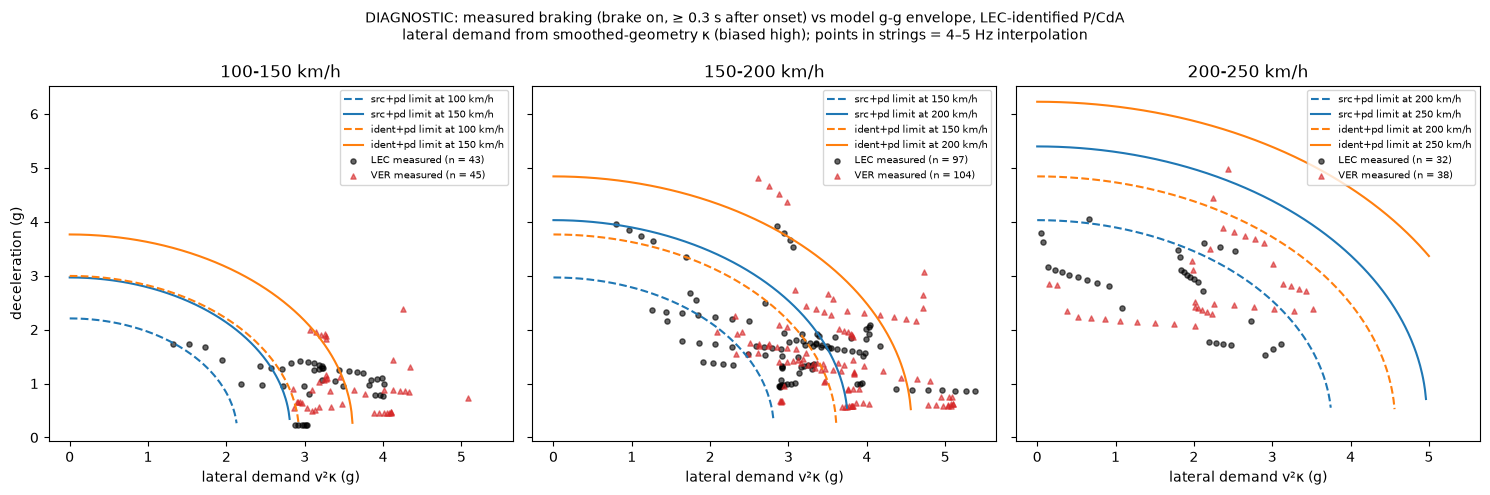

In [59]:
# =================================
# Diagnosis with the braking g-g filter
# =================================

def envelope(ay_g, v, car, rho):
    """Model braking limit (g) vs lateral demand (g) at speed v: ellipse tyre term + drag."""
    k = rho * car['ClA'] / (2 * car['m'])
    lim_y = car['mu_y'] * (G + k * v**2) / G
    lim_x = car['mu_x'] * (G + k * v**2) / G
    drag = rho * car['CdA'] / (2 * car['m']) * v**2 / G
    tyre = lim_x * np.sqrt(np.clip(1 - (ay_g / lim_y)**2, 0, None))
    return np.where(ay_g <= lim_y, tyre + drag, np.nan)

bands_plot = [(100, 150), (150, 200), (200, 250)]
rho = drivers['LEC']['rho']
ay = np.linspace(0, 5, 400)
colours = {'src+pd': 'tab:blue', 'ident+pd': 'tab:orange'}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (lo, hi) in zip(axes, bands_plot):
    for name, car in cars.items():
        for v_kmh, ls in [(lo, '--'), (hi, '-')]:
            ax.plot(ay, envelope(ay, v_kmh / 3.6, car, rho), ls=ls, color=colours[name],
                    label=f"{name} limit at {v_kmh} km/h")
    for drv, mk, col in [('LEC', 'o', 'k'), ('VER', '^', 'tab:red')]:
        df = brake_pts[drv]
        sub = df[(df['v_kmh'] > lo) & (df['v_kmh'] <= hi)]
        ax.scatter(sub['lat_g'], sub['meas_g'], marker=mk, s=14, alpha=0.6, color=col,
                   label=f"{drv} measured (n = {len(sub)})")
    ax.set_title(f"{lo}-{hi} km/h")
    ax.set_xlabel("lateral demand v²κ (g)")
    ax.legend(fontsize=7, loc='upper right')
axes[0].set_ylabel("deceleration (g)")
fig.suptitle("DIAGNOSTIC: measured braking (brake on, ≥ 0.3 s after onset) vs model g-g envelope, "
             "LEC-identified P/CdA\nlateral demand from smoothed-geometry κ (biased high); "
             "points in strings = 4–5 Hz interpolation", fontsize=10)
fig.tight_layout()
fig.savefig('../figures/05_braking_gg.png', dpi=150)
plt.show()

In [60]:
# =================================
# Zone totals for every diagnosis run
# =================================

runs = {'Sourced':               CAR_2022,
        '+ P/CdA':               {**CAR_2022, **pd_fit},
        '+ P/CdA + RWD':         {**CAR_2022, **pd_fit, **RWD_2022},
        'Ident + P/CdA':         {**CAR_2022_FIT, **pd_fit},
        'Ident + P/CdA + RWD':   {**CAR_2022_FIT, **pd_fit, **RWD_2022}}

headline = {}
for drv, d in drivers.items():
    geo, rho = d['geo'], d['rho']
    s = geo['s'].to_numpy()
    v_meas = geo['v'].to_numpy()
    rows = {}
    for name, car in runs.items():
        res = solve_lap(geo, car, rho, d['v_start'], d['v_end'])
        zone = classify_zones(geo, res, car, rho)
        seg = segment_table(s, res['v'], v_meas, zone, d['bounds'])
        rows[name] = zone_totals(seg).reindex(ZONES)['dt']
    headline[drv] = pd.DataFrame(rows).T
    headline[drv]['total'] = headline[drv][ZONES].sum(axis=1)
    print(f"\n{drv} (model - measured, s; zones split half-start / half-end)")
    print(headline[drv].round(3))


LEC (model - measured, s; zones split half-start / half-end)
                     cornering  braking  accel_grip  accel_power  total
Sourced                  0.183    2.659       1.390       -1.377  2.855
+ P/CdA                  0.183    2.774       1.388        0.329  4.673
+ P/CdA + RWD            0.182    2.821       2.512        1.310  6.825
Ident + P/CdA            0.034   -0.192      -0.239       -3.463 -3.860
Ident + P/CdA + RWD      0.037   -0.141      -0.603       -2.255 -2.962

VER (model - measured, s; zones split half-start / half-end)
                     cornering  braking  accel_grip  accel_power  total
Sourced                  0.193    2.968       1.208       -1.770  2.600
+ P/CdA                  0.195    3.092       1.272       -0.062  4.498
+ P/CdA + RWD            0.195    3.130       2.269        1.037  6.631
Ident + P/CdA            0.045    0.061      -0.243       -3.737 -3.873
Ident + P/CdA + RWD      0.045    0.091      -0.642       -2.533 -3.039


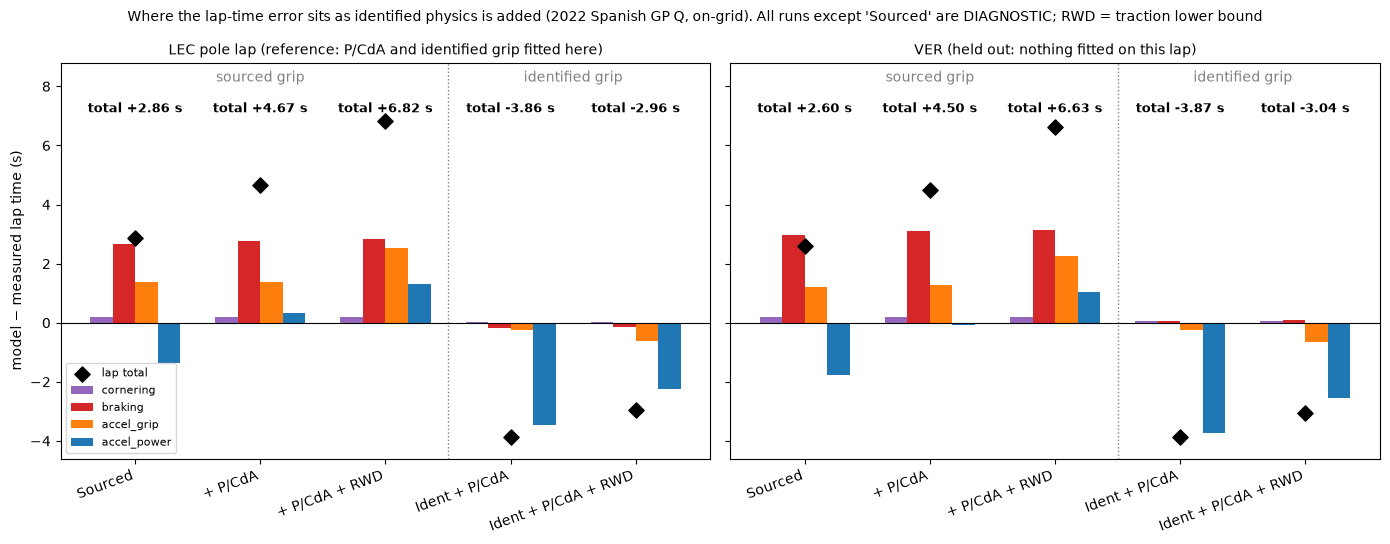

In [62]:
# =================================
# Final figure
# =================================

zone_col = {'cornering': 'tab:purple', 'braking': 'tab:red',
            'accel_grip': 'tab:orange', 'accel_power': 'tab:blue'}
titles = {'LEC': 'LEC pole lap (reference: P/CdA and identified grip fitted here)',
          'VER': 'VER (held out: nothing fitted on this lap)'}
x = np.arange(len(runs))
w = 0.18

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, (drv, tab) in zip(axes, headline.items()):
    for i, z in enumerate(ZONES):
        ax.bar(x + (i - 1.5) * w, tab[z], width=w, color=zone_col[z], label=z)
    ax.scatter(x, tab['total'], marker='D', s=60, color='k', zorder=3, label='lap total')
    for xi, tot in zip(x, tab['total']):
        ax.text(xi, 0.90, f"total {tot:+.2f} s", transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=9, fontweight='bold')
    ax.axhline(0, color='k', lw=0.8)
    ax.axvline(2.5, color='grey', ls=':', lw=1)
    ax.text(1, 0.98, 'sourced grip', transform=ax.get_xaxis_transform(),
            ha='center', va='top', color='grey')
    ax.text(3.5, 0.98, 'identified grip', transform=ax.get_xaxis_transform(),
            ha='center', va='top', color='grey')
    ax.set_xticks(x)
    ax.set_xticklabels(tab.index, rotation=20, ha='right')
    ax.set_title(titles[drv], fontsize=10)
axes[0].set_ylabel('model − measured lap time (s)')
axes[0].legend(fontsize=8, loc='lower left')
fig.suptitle("Where the lap-time error sits as identified physics is added "
             "(2022 Spanish GP Q, on-grid). All runs except 'Sourced' are DIAGNOSTIC; "
             "RWD = traction lower bound", fontsize=10)
axes[0].set_ylim(-4.6, 8.8)
fig.tight_layout()
fig.savefig('../figures/05_headline_zones.png', dpi=150)
plt.show()